<a href="https://colab.research.google.com/github/Violetaaa/tfg-learning/blob/main/04_gis_with_python/07_vecino_mas_cercano.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6.7 Vecino más cercano (resumen)

Resumen del capítulo *Nearest neighbour analysis* de *Python for Geographic Data Analysis* (Tenkanen et al., pythongis.org), reducido a lo que se usa en el TFG. El libro usa datos de Helsinki; aquí se usan tus datos de Asturias.

**Idea clave:** para cada geometría de una capa, buscar la más cercana de otra capa y a qué distancia está. En el TFG es la operación central: *«¿cuál es la farmacia más cercana a este núcleo y a cuántos km está?»*.

⚠️ Todo lo de este capítulo es **distancia en línea recta (euclídea)**, no por carretera. En zona rural de montaña la diferencia puede ser grande; la distancia por red de carreteras es otro paso.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# Folder that contains raw/ and asturias_miteco.gpkg. In Colab, e.g. Path("/content/drive/MyDrive/tfg/datos").
DATA_DIR = Path("/content/drive/MyDrive/tfg/")
CRS_METRES = "EPSG:25830"


def load_layer(pattern):
    """Read the latest raw download matching a pattern and reproject it to metres."""
    path = sorted(DATA_DIR.glob(f"sitpa_raw_data/{pattern}"))[-1]
    return gpd.read_file(path).to_crs(CRS_METRES)


municipalities = gpd.read_file(DATA_DIR / "miteco_data/out/asturias_miteco.gpkg").to_crs(CRS_METRES)
pharmacies = load_layer("farmacias_botiquines__farmacias_*.geojson")

import json

# Settlements of Candamo (OSM, cached in the MVP). Adjust the path in Colab.
SETTLEMENTS_FP = DATA_DIR / "mvp_data" / "datos_Candamo.json"
with open(SETTLEMENTS_FP, encoding="utf-8") as f:
    settlements_df = pd.DataFrame(json.load(f)["nucleos"])

settlements = gpd.GeoDataFrame(
    settlements_df,
    geometry=gpd.points_from_xy(settlements_df["lon"], settlements_df["lat"]),
    crs="EPSG:4326",
).to_crs(CRS_METRES)
print(len(settlements), "settlements |", len(pharmacies), "pharmacies")

54 settlements | 454 pharmacies


## `sjoin_nearest`: la más cercana
Funciona como `sjoin` (6.6), pero la condición es «la más cercana». `distance_col` añade la distancia en unidades del CRS, en este caso metros.

In [4]:
nearest = settlements.sjoin_nearest(
    pharmacies[["titular", "poblacion", "geometry"]],
    distance_col="distance_m",
)
nearest[["nombre", "titular", "poblacion", "distance_m"]].sort_values("distance_m", ascending=False).head()

,nombre,titular,poblacion,distance_m
48,Ventosa,JORGE RUIZ REY,SAN ROMAN DE CANDAMO,6368.804338
9,Las Pandiellas,JORGE RUIZ REY,SAN ROMAN DE CANDAMO,5802.321034
52,La Reigada,LUCIA CASTAN FERNANDEZ,ILLAS,5736.039956
45,Argañosa,LUCIA CASTAN FERNANDEZ,ILLAS,5657.197458
47,Las Paciones,JORGE RUIZ REY,SAN ROMAN DE CANDAMO,5632.023925


In [6]:
nearest["distance_m"].describe().round(0)

,distance_m
count,54.0
mean,3521.0
std,1493.0
min,342.0
25%,2617.0
50%,3408.0
75%,4618.0
max,6369.0


Dos detalles que afectan a los resultados:
- **Empates:** si dos farmacias están exactamente a la misma distancia, el núcleo aparece **dos veces**. Compara `len()` antes y después, o quédate con una fila con `nearest[~nearest.index.duplicated()]`.
- **`max_distance=5000`:** limita la búsqueda (y la acelera). Los núcleos sin ninguna farmacia dentro de ese radio desaparecen del resultado, igual que en un *inner join*.

In [7]:
print(len(settlements), "->", len(nearest), "rows (more rows would mean ties)")

within_5km = settlements.sjoin_nearest(pharmacies[["geometry"]], max_distance=5000, distance_col="distance_m")
print(len(within_5km), "settlements have a pharmacy within 5 km")

54 -> 54 rows (more rows would mean ties)
41 settlements have a pharmacy within 5 km


## Ver las conexiones en un mapa
`shapely.shortest_line(a, b)` crea la línea más corta entre dos geometrías. Sirve para comprobar visualmente que el emparejamiento tiene sentido.

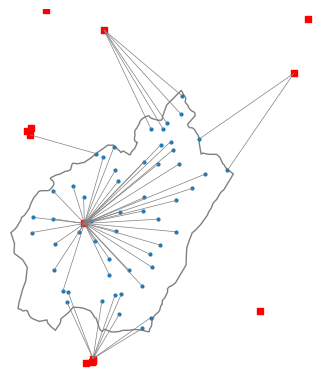

In [8]:
from shapely import shortest_line

matched_pharmacies = pharmacies.geometry.loc[nearest["index_right"]].values
links = gpd.GeoSeries(shortest_line(nearest.geometry.values, matched_pharmacies), crs=CRS_METRES)

ax = municipalities[municipalities["nombre"] == "Candamo"].plot(facecolor="none", edgecolor="gray")
links.plot(ax=ax, linewidth=0.5, color="gray")
settlements.plot(ax=ax, markersize=4)
pharmacies.plot(ax=ax, color="red", markersize=20, marker="s")
ax.set_xlim(*links.total_bounds[[0, 2]] + [-1000, 1000])
ax.set_ylim(*links.total_bounds[[1, 3]] + [-1000, 1000])
ax.set_axis_off()

Fíjate en que muchos núcleos de Candamo tienen la farmacia más cercana **en otro concejo**: con los datos actuales, 16 de 54 (Grado, Soto del Barco, Illas y Pravia). Por eso el agente no debe buscar servicios solo dentro del concejo del usuario.

## Las k más cercanas (`KDTree`)
`sjoin_nearest` solo da la primera. Para la 2.ª, 3.ª… se usa un `KDTree` de scipy sobre las coordenadas, en forma de array de numpy. Es útil para alternativas («si la más cercana está cerrada…»).

In [9]:
from scipy.spatial import KDTree

pharmacy_tree = KDTree(pharmacies.get_coordinates().to_numpy())
dist, idx = pharmacy_tree.query(settlements.get_coordinates().to_numpy(), k=3)  # arrays of shape (n_settlements, 3)

first = settlements.iloc[0]["nombre"]
print(f"3 nearest pharmacies to {first}:")
for d, i in zip(dist[0], idx[0]):
    print(f"  {pharmacies.iloc[i]['titular']} ({pharmacies.iloc[i]['poblacion']}) - {d / 1000:.1f} km")

3 nearest pharmacies to Grullos:
  JORGE RUIZ REY (SAN ROMAN DE CANDAMO) - 2.1 km
  LETICIA SOBRINO LLORCA (GRADO) - 5.0 km
  NICOLAS DE LAS HERAS MONFORTE (GRADO) - 5.1 km


`idx` contiene **posiciones** (para usar con `.iloc`), no etiquetas del índice.

## Todas las que hay dentro de un radio
¿Cuántas farmacias hay a menos de 5 km de cada núcleo? Con `sjoin` y `predicate="dwithin"` (GeoPandas ≥ 1.0) no hace falta crear buffers.

In [11]:
in_radius = settlements.sjoin(pharmacies[["geometry"]], predicate="dwithin", distance=5000)
counts = in_radius.groupby("nombre").size().reindex(settlements["nombre"], fill_value=0)
counts.sort_values().head()

,0
nombre,
Las Pandiellas,0
Pulide,0
Reznera,0
Tabláu,0
Ventosa,0


La alternativa del libro es `buffer(5000)` más `sjoin(predicate="intersects")`: da lo mismo y es más lenta. `KDTree.query_ball_point` también sirve.

## Lo que se ha omitido del capítulo
- Vecino más cercano entre **polígonos o líneas** (edificio-parque, edificio-carretera): funciona igual con `sjoin_nearest`.
- Construir las líneas de las k vecinas con `merge` + `apply`: la versión de arriba es más corta.

Documentación: https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.sjoin_nearest.html